# Text-length confounding and length-matched sensitivity evaluation

**Independent, testable diagnostic for the two Vietnamese depression-related text benchmarks.** This analysis uses only document length to create new baselines and **reuses frozen model predictions** to evaluate performance among length-matched held-out texts. No textual content is transmitted to any external service or saved to the output tables.

**Scope and provenance.** It uses the `datasets/dataset_1.csv` and `datasets/dataset_2.csv` files and reproduction artifacts in this repository. D1 and D2 share the same 3,782 positive texts but have different control sources. Labels are corpus annotations, **not clinical diagnoses**. Reference-positive texts have English-language origins and were translated into Vietnamese; length matching does **not** eliminate translation/source confounding.

**Prespecified analysis:** stratified 80/20 split with `random_state=42` (matching the *DL/PhoBERT and GPT* protocol); features based only on raw character length and whitespace-delimited token count; Logistic Regression and a shallow Decision Tree trained only on the training 80%; one-to-one deterministic coarsened-exact matching in fixed log-character-length bins of width log(1.25), using equal quantile positions within each bin. This guarantees paired texts differ by less than a factor of 1.25 in (characters + 1). Include sensitivity bin widths log(1.10) and log(1.50). Exact held-out prediction IDs and labels are validated before reuse.

**Different TF–IDF protocol:** TF–IDF removed rows during legacy preprocessing and uses a distinct held-out split (D1 n=1185, D2 n=1450). We include a separately labeled *matched-test prediction sensitivity* check on its archived predictions. We **do not** falsely treat the DL-split length-only models as TF–IDF-split baselines. Reproduction of a directly comparable TF–IDF length-only baseline requires recreating the historical preprocessing (`underthesea==8.3.0`, `py_vncorenlp==0.1.4`).

**Important unavailable evaluation:** PhoBERT-large predictions are not included in this archive (the reproduction report notes GPU out-of-memory). Its 99%-range archived results must not be relabeled as a length-matched result here.

**Data access warning:** The uploaded archive contains raw `datasets/*.csv` despite its `DATA_AND_PRIVACY.md` stating those files are withheld from public snapshots. Do not publish the private data or the local-output row-level files without permissions. For public reproducibility share the notebook, aggregate CSVs, scripts, and hashes; users with permitted access can add the source CSVs themselves.

In [1]:
from pathlib import Path
import hashlib, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
    f1_score, recall_score, roc_auc_score, confusion_matrix)

# Locate the checkout even when Jupyter is launched from its notebooks/ folder.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'datasets/dataset_1.csv').is_file() and
                (p/'gpt56_sol/results/d1_predictions_public.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Repository root not found. Place this notebook in the supplied repo, '
                            'and supply datasets/dataset_1.csv and dataset_2.csv locally.')
OUT = ROOT/'length_confounds_results'
OUT.mkdir(exist_ok=True)
print('Project:', ROOT, '\nOutputs:', OUT)
print('sklearn:', __import__('sklearn').__version__, 'pandas:', pd.__version__)

Project: c:\Users\it08d\OneDrive - kcg.ac.jp\_KCGI\_Projects\_Done\Depression_Thay Cach\vietnamese-depression-nlp 
Outputs: c:\Users\it08d\OneDrive - kcg.ac.jp\_KCGI\_Projects\_Done\Depression_Thay Cach\vietnamese-depression-nlp\length_confounds_results
sklearn: 1.9.1 pandas: 3.0.6


## 1 · Frozen-input integrity and held-out split reconstruction

In [2]:
EXPECTED_SHA256 = {
  1:'b2ad99ebdcf3c34f040a2988fda1c482e9ff9b9cf42795bb64c792b3c7043d9e',
  2:'88161f9388194bbb9cede048223d8f7f6bc6ab68670c373eeffd13bbb45de842'
}
TRAIN, TEST, FULL = {}, {}, {}
for d in [1, 2]:
    file = ROOT/f'datasets/dataset_{d}.csv'
    actual_hash = hashlib.sha256(file.read_bytes()).hexdigest()
    assert actual_hash == EXPECTED_SHA256[d], f'D{d}: source data hash differs from frozen study input'
    df = pd.read_csv(file).copy()
    assert list(df.columns) == ['text_vi', 'sentiment']
    assert df.text_vi.notna().all() and df.sentiment.isin([0,1]).all()
    df['source_row_id'] = np.arange(len(df), dtype=int)
    df['characters'] = df.text_vi.astype(str).str.len()
    df['whitespace_tokens'] = df.text_vi.astype(str).str.split().str.len()
    assert df.characters.ge(0).all()
    train, test = train_test_split(df, test_size=0.2,
                                   random_state=42, stratify=df.sentiment)
    FULL[d], TRAIN[d], TEST[d] = df, train.copy(), test.copy()
    print(f'D{d}: full={len(df):,} train={len(train):,} test={len(test):,}; '
          f'test labels={test.sentiment.value_counts().sort_index().to_dict()}; hash OK')

# Verify exactly against the saved outer-test records, not simply test size.
for d in [1,2]:
    for model in ['phobert_base','word2vec_plus_cnn','word2vec_plus_bilstm']:
        path = ROOT/f'reproduction_results/runs/{model}/d{d}/predictions.csv'
        pred = pd.read_csv(path)
        assert pred.source_row_id.is_unique
        assert set(pred.source_row_id) == set(TEST[d].source_row_id), f'{model}, D{d} test split mismatch'
        gold = FULL[d].set_index('source_row_id').loc[pred.source_row_id, 'sentiment'].to_numpy()
        assert np.array_equal(pred.gold_label.to_numpy(), gold)
    gpt = pd.read_csv(ROOT/f'gpt56_sol/results/d{d}_predictions_public.csv')
    assert gpt.source_row_id.is_unique
    assert set(gpt.source_row_id) == set(TEST[d].source_row_id), f'GPT D{d}: split mismatch'
    gold = FULL[d].set_index('source_row_id').loc[gpt.source_row_id, 'sentiment'].to_numpy()
    assert np.array_equal(gpt.gold_label.to_numpy(), gold)
print('PASS — exact source IDs and labels match all DL/GPT archived prediction files.')

D1: full=5,933 train=4,746 test=1,187; test labels={0: 430, 1: 757}; hash OK
D2: full=7,345 train=5,876 test=1,469; test labels={0: 713, 1: 756}; hash OK
PASS — exact source IDs and labels match all DL/GPT archived prediction files.


## 2 · Character and whitespace-token length distributions (raw texts)

,dataset,label,n,chars_mean,chars_median,chars_p10,chars_p90,tokens_mean,tokens_median
0,D1,0,2151,867.4,294.0,58.0,2122.0,193.6,68.0
1,D1,1,3782,716.4,404.5,79.0,1654.9,163.9,92.5
2,D2,0,3563,49.0,41.0,19.0,88.0,12.2,10.0
3,D2,1,3782,716.4,404.5,79.0,1654.9,163.9,92.5


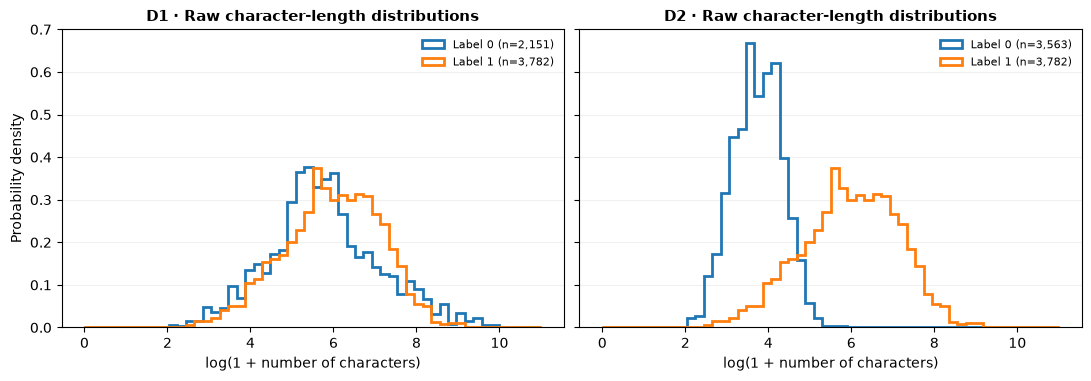

In [3]:
desc=[]
for d in [1,2]:
    for label in [0,1]:
        s=FULL[d].loc[FULL[d].sentiment==label]
        desc.append({'dataset':f'D{d}','label':label,'n':len(s),
          'chars_mean':s.characters.mean(),'chars_median':s.characters.median(),
          'chars_p10':s.characters.quantile(.1),'chars_p90':s.characters.quantile(.9),
          'tokens_mean':s.whitespace_tokens.mean(), 'tokens_median':s.whitespace_tokens.median()})
length_descriptives=pd.DataFrame(desc)
length_descriptives.to_csv(OUT/'length_descriptives.csv',index=False)
display(length_descriptives.round(1))

fig,axs=plt.subplots(1,2,figsize=(10.8,3.7),sharey=True,constrained_layout=True)
for ax,d in zip(axs,[1,2]):
    # Plot distributions as density curves of log1p(character count).
    for label in [0,1]:
        raw=np.log1p(FULL[d].loc[FULL[d].sentiment==label,'characters'])
        ax.hist(raw,bins=np.linspace(0,11,55),density=True,histtype='step',
                linewidth=2,label=f'Label {label} (n={len(raw):,})')
    ax.set_title(f'D{d} · Raw character-length distributions',fontsize=11,weight='bold')
    ax.set_xlabel('log(1 + number of characters)')
    ax.grid(axis='y',alpha=.18)
    ax.legend(frameon=False,fontsize=8)
axs[0].set_ylabel('Probability density')
fig.savefig(OUT/'figure_length_distributions.pdf',bbox_inches='tight')
plt.show()

## 3 · Train length-only classifiers on the exact historical DL/GPT train/test split

No vectorization or semantic tokens are used. The whitespace-delimited count is *not* a Vietnamese lexical-word count. Feature scaling is learned **only from training data**. Hyperparameters are fixed rather than chosen on the test set.

In [4]:
def extract_X(df):
    return np.log1p(df[['characters','whitespace_tokens']].to_numpy(dtype=float))

def metric_row(y, pred, prob=None):
    y=np.asarray(y,dtype=int); pred=np.asarray(pred,dtype=int)
    out={'n':int(len(y)), 'class0_n':int((y==0).sum()),'class1_n':int((y==1).sum()),
         'accuracy':accuracy_score(y,pred),
         'balanced_accuracy':balanced_accuracy_score(y,pred),
         'macro_f1':f1_score(y,pred,average='macro',zero_division=0),
         'class1_f1':f1_score(y,pred,pos_label=1,zero_division=0),
         'class1_recall':recall_score(y,pred,pos_label=1,zero_division=0),
         'class0_recall':recall_score(y,pred,pos_label=0,zero_division=0)}
    if prob is not None and len(np.unique(y))==2:
        out['roc_auc']=roc_auc_score(y,np.asarray(prob,dtype=float))
    else: out['roc_auc']=np.nan
    return out

MODELS={
    'Majority class':lambda:DummyClassifier(strategy='most_frequent'),
    'Length-LR (characters)':lambda:make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,random_state=42)),
    'Length-LR (tokens)':lambda:make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,random_state=42)),
    'Length-LR (both)':lambda:make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,random_state=42)),
    'Length-tree (both)':lambda:DecisionTreeClassifier(max_depth=3,min_samples_leaf=20,random_state=42)
}
length_rows=[]; length_pred_rows=[]
for d in [1,2]:
    tr,te=TRAIN[d],TEST[d]
    Xtr,Xte=extract_X(tr),extract_X(te)
    for model_name, constructor in MODELS.items():
        idx=([0] if 'characters' in model_name else
             [1] if '(tokens)' in model_name else [0,1])
        clf=constructor()
        clf.fit(Xtr[:,idx],tr.sentiment.to_numpy())
        predicted=clf.predict(Xte[:,idx]).astype(int)
        proba=(clf.predict_proba(Xte[:,idx])[:,1] if hasattr(clf,'predict_proba') else None)
        length_rows.append({'dataset':f'D{d}','model':model_name,
                            **metric_row(te.sentiment,predicted,proba)})
        for sid,gold,p,score in zip(te.source_row_id,te.sentiment,predicted,
                                     proba if proba is not None else np.full(len(te),np.nan)):
            length_pred_rows.append({'dataset':f'D{d}','source_row_id':int(sid),
                  'gold_label':int(gold),'model':model_name,'predicted_label':int(p),
                  'class1_score':float(score)})
length_baselines=pd.DataFrame(length_rows)
length_predictions=pd.DataFrame(length_pred_rows)
length_baselines.to_csv(OUT/'length_only_baselines.csv',index=False)
length_predictions.to_csv(OUT/'length_only_test_predictions_NO_TEXT.csv',index=False)
display(length_baselines[['dataset','model','n','accuracy','balanced_accuracy','macro_f1','class1_recall','roc_auc']].round(3))

,dataset,model,n,accuracy,balanced_accuracy,macro_f1,class1_recall,roc_auc
0,D1,Majority class,1187,0.638,0.500,0.389,1.000,0.500
1,D1,Length-LR (characters),1187,0.638,0.500,0.389,1.000,0.568
2,D1,Length-LR (tokens),1187,0.638,0.500,0.389,1.000,0.564
3,D1,Length-LR (both),1187,0.639,0.501,0.392,1.000,0.581
4,D1,Length-tree (both),1187,0.645,0.515,0.430,0.988,0.591
5,D2,Majority class,1469,0.515,0.500,0.340,1.000,0.500
6,D2,Length-LR (characters),1469,0.912,0.912,0.912,0.888,0.958
7,D2,Length-LR (tokens),1469,0.900,0.901,0.900,0.873,0.949
8,D2,Length-LR (both),1469,0.927,0.928,0.927,0.910,0.968
9,D2,Length-tree (both),1469,0.910,0.912,0.910,0.841,0.955


## 4 · Reuse archived test predictions from the same held-out split

Saved results come from **PhoBERT-base**, **Word2Vec+CNN**, **Word2Vec+BiLSTM**, and **GPT-5.6 Sol**. The table is descriptive and includes the length-only models for direct same-split comparison. PhoBERT-large has no saved prediction file here.

In [5]:
archived=[]
for d in [1,2]:
    for slug,name in [('phobert_base','PhoBERT-base'),
                      ('word2vec_plus_cnn','Word2Vec+CNN'),
                      ('word2vec_plus_bilstm','Word2Vec+BiLSTM')]:
        p=pd.read_csv(ROOT/f'reproduction_results/runs/{slug}/d{d}/predictions.csv')
        p['model']=name;p['dataset']=f'D{d}'
        archived.append(p[['dataset','model','source_row_id','gold_label','predicted_label']])
    p=pd.read_csv(ROOT/f'gpt56_sol/results/d{d}_predictions_public.csv')
    p['model']='GPT-5.6 Sol';p['dataset']=f'D{d}'
    archived.append(p[['dataset','model','source_row_id','gold_label','predicted_label']])
archived=pd.concat(archived,ignore_index=True)
all_preds=pd.concat([archived,length_predictions[['dataset','model','source_row_id','gold_label','predicted_label']]],ignore_index=True)
assert not all_preds.duplicated(['dataset','model','source_row_id']).any()
full_results=[]
for (d,m),g in all_preds.groupby(['dataset','model'],sort=True):
    full_results.append({'dataset':d,'model':m,'sample':'Original held-out',
                         **metric_row(g.gold_label,g.predicted_label)})
full_results=pd.DataFrame(full_results)
full_results.to_csv(OUT/'original_test_metrics_verified.csv',index=False)
display(full_results[['dataset','model','n','accuracy','balanced_accuracy','macro_f1','class1_recall']].round(3))

,dataset,model,n,accuracy,balanced_accuracy,macro_f1,class1_recall
0,D1,GPT-5.6 Sol,1187,0.938,0.949,0.934,0.909
1,D1,Length-LR (both),1187,0.639,0.501,0.392,1.000
2,D1,Length-LR (characters),1187,0.638,0.500,0.389,1.000
3,D1,Length-LR (tokens),1187,0.638,0.500,0.389,1.000
4,D1,Length-tree (both),1187,0.645,0.515,0.430,0.988
5,D1,Majority class,1187,0.638,0.500,0.389,1.000
6,D1,PhoBERT-base,1187,0.976,0.971,0.973,0.988
7,D1,Word2Vec+BiLSTM,1187,0.970,0.968,0.967,0.974
8,D1,Word2Vec+CNN,1187,0.979,0.975,0.977,0.988
9,D2,GPT-5.6 Sol,1469,0.935,0.937,0.935,0.889


## 5 · Prespecified, label-balanced held-out length matching

**Coarsened-exact matching rule:** independently for D1 and D2, divide held-out observations into fixed bins defined as `floor(log1p(raw character count) / log(1.25))`. Within each bin take `min(n_label0, n_label1)` documents from each label, selected deterministically at equally spaced quantile ranks; sort selected texts by length and match one-to-one. Bin width guarantees an absolute log-length difference < `log(1.25)` for each pair. This uses **labels and lengths only**, never model predictions. Sensitivity analyses repeat the procedure using fixed bin widths `log(1.10)` and `log(1.50)`.

This design balances the length distribution more closely than a simple sequential greedy caliper match and avoids reusing an observation. It is a **post-hoc evaluation subset**, not a matched retraining experiment. Its exact bins are deterministic, but changing bin boundaries can change the selected sample.

Matching can substantially change class prevalence and exclude most D2 texts. Always report matched sample size and fraction retained; emphasize balanced accuracy, macro-F1, and residual log-length standardized mean differences. Do not imply that matched accuracy estimates population performance on the original corpora.

In [6]:
def match_by_length(te, ratio=1.25):
    """Deterministic coarsened-exact matching in log-character bins.

    Pair within shared bins; choose equal quantile positions within larger classes
    rather than concentrating on one end of a bin.
    """
    t=te[['source_row_id','sentiment','characters','whitespace_tokens']].copy()
    width=np.log(ratio)
    t['log_chars']=np.log1p(t['characters'].to_numpy())
    t['length_bin']=np.floor(t.log_chars / width).astype(int)
    pairs=[]
    for _,g in t.groupby('length_bin',sort=True):
        a=g.loc[g.sentiment==0].sort_values(['log_chars','source_row_id']).reset_index(drop=True)
        b=g.loc[g.sentiment==1].sort_values(['log_chars','source_row_id']).reset_index(drop=True)
        n=min(len(a),len(b))
        if not n:
            continue
        ia=np.floor((np.arange(n)+.5)*len(a)/n).astype(int)
        ib=np.floor((np.arange(n)+.5)*len(b)/n).astype(int)
        selected0=a.iloc[ia].reset_index(drop=True)
        selected1=b.iloc[ib].reset_index(drop=True)
        for j in range(n):
            pairs.append((int(selected0.loc[j,'source_row_id']),
                          int(selected1.loc[j,'source_row_id']),
                          float(abs(selected0.loc[j,'log_chars']-selected1.loc[j,'log_chars']))))
    return pd.DataFrame(pairs,columns=['source_id_label0','source_id_label1','abs_log_char_difference'])

match_summaries=[]; matched_ids={}; matched_pairs={}; sensitivity=[]
for d in [1,2]:
    te=TEST[d]
    for ratio in (1.10,1.25,1.50):
        pairs=match_by_length(te,ratio)
        sensitivity.append({'dataset':f'D{d}','bin_width_ratio':ratio,
                            'matched_pairs':len(pairs),'matched_documents':2*len(pairs),
                            'test_coverage':2*len(pairs)/len(te)})
    pairs=match_by_length(te,1.25)
    assert len(pairs)>0 and not pairs.source_id_label0.duplicated().any() and not pairs.source_id_label1.duplicated().any()
    ids=set(pairs.source_id_label0)|set(pairs.source_id_label1)
    assert len(ids)==2*len(pairs)
    matched_ids[f'D{d}']=ids; matched_pairs[d]=pairs
    sub=te[te.source_row_id.isin(ids)]
    z0=np.log1p(sub[sub.sentiment==0].characters);z1=np.log1p(sub[sub.sentiment==1].characters)
    smd=(z1.mean()-z0.mean())/np.sqrt((z1.var(ddof=1)+z0.var(ddof=1))/2)
    match_summaries.append({'dataset':f'D{d}','test_n':len(te),'matched_pairs':len(pairs),
                            'matched_n':len(sub),'test_coverage':len(sub)/len(te),
                            'max_abs_log_char_diff':pairs.abs_log_char_difference.max(),
                            'matched_log_char_smd':smd,
                            'matched_label0_median_chars':sub.loc[sub.sentiment==0,'characters'].median(),
                            'matched_label1_median_chars':sub.loc[sub.sentiment==1,'characters'].median()})
matching=pd.DataFrame(match_summaries)
matching_sensitivity=pd.DataFrame(sensitivity)
matching.to_csv(OUT/'length_match_coverage_and_balance.csv',index=False)
matching_sensitivity.to_csv(OUT/'caliper_sensitivity_counts.csv',index=False)
for d,pairs in matched_pairs.items():
    pairs.to_csv(OUT/f'D{d}_matched_pair_ids_LOCAL.csv',index=False)
display(matching.round(3))
display(matching_sensitivity.round(3))

,dataset,test_n,matched_pairs,matched_n,test_coverage,max_abs_log_char_diff,matched_log_char_smd,matched_label0_median_chars,matched_label1_median_chars
0,D1,1187,410,820,0.691,0.129,-0.004,286.5,292.0
1,D2,1469,133,266,0.181,0.117,0.022,78.0,79.0


,dataset,bin_width_ratio,matched_pairs,matched_documents,test_coverage
0,D1,1.10,388,776,0.654
1,D1,1.25,410,820,0.691
2,D1,1.50,417,834,0.703
3,D2,1.10,127,254,0.173
4,D2,1.25,133,266,0.181
5,D2,1.50,131,262,0.178


## 6 · Existing predictions on the matched held-out subset

In [7]:
matched_metrics=[]
for (d,m),g in all_preds.groupby(['dataset','model'],sort=True):
    selected=g[g.source_row_id.isin(matched_ids[d])]
    assert len(selected)==len(matched_ids[d]),f'{m} missing matched IDs on {d}'
    matched_metrics.append({'dataset':d,'model':m,'sample':'Length-matched (25% bins)',
                            **metric_row(selected.gold_label,selected.predicted_label)})
matched_metrics=pd.DataFrame(matched_metrics)
matched_metrics.to_csv(OUT/'matched_test_metrics.csv',index=False)
side_by_side=full_results.merge(matched_metrics,on=['dataset','model'],suffixes=('_full','_matched'))
side_by_side['delta_balanced_accuracy']=side_by_side.balanced_accuracy_matched-side_by_side.balanced_accuracy_full
side_by_side['delta_macro_f1']=side_by_side.macro_f1_matched-side_by_side.macro_f1_full
side_by_side.to_csv(OUT/'full_vs_length_matched_results.csv',index=False)
display(side_by_side[['dataset','model','n_full','n_matched',
  'balanced_accuracy_full','balanced_accuracy_matched','delta_balanced_accuracy',
  'macro_f1_full','macro_f1_matched','delta_macro_f1','class1_recall_matched']].round(3))

,dataset,model,n_full,n_matched,balanced_accuracy_full,balanced_accuracy_matched,delta_balanced_accuracy,macro_f1_full,macro_f1_matched,delta_macro_f1,class1_recall_matched
0,D1,GPT-5.6 Sol,1187,820,0.949,0.950,0.001,0.934,0.950,0.015,0.912
1,D1,Length-LR (both),1187,820,0.501,0.500,-0.001,0.392,0.333,-0.059,1.000
2,D1,Length-LR (characters),1187,820,0.500,0.500,0.000,0.389,0.333,-0.056,1.000
3,D1,Length-LR (tokens),1187,820,0.500,0.500,0.000,0.389,0.333,-0.056,1.000
4,D1,Length-tree (both),1187,820,0.515,0.507,-0.008,0.430,0.363,-0.066,0.983
5,D1,Majority class,1187,820,0.500,0.500,0.000,0.389,0.333,-0.056,1.000
6,D1,PhoBERT-base,1187,820,0.971,0.968,-0.003,0.973,0.968,-0.005,0.983
7,D1,Word2Vec+BiLSTM,1187,820,0.968,0.972,0.004,0.967,0.972,0.005,0.976
8,D1,Word2Vec+CNN,1187,820,0.975,0.973,-0.002,0.977,0.973,-0.004,0.980
9,D2,GPT-5.6 Sol,1469,266,0.937,0.895,-0.042,0.935,0.894,-0.041,0.827


## 7 · Optional: TF–IDF model test-only sensitivity on its **distinct** holdout

The original 12/96 preprocessing-excluded rows and full preprocessed CSVs are absent. Therefore we can safely subset **saved TF–IDF test predictions** by raw length and verify their IDs/gold labels, but not claim a comparable TF–IDF length-only training baseline from the raw 80/20 DL split.

In [8]:
tfidf_rows=[];tfidf_coverage=[]
for d in [1,2]:
    tfidf_path=ROOT/f'reproduction_results/runs/tf_idf_plus_lr/d{d}/predictions.csv'
    p=pd.read_csv(tfidf_path)
    q=FULL[d].set_index('source_row_id').loc[p.source_row_id].copy().reset_index(drop=True)
    assert np.array_equal(q.sentiment.to_numpy(),p.gold_label.to_numpy())
    q['source_row_id']=p.source_row_id.to_numpy()
    pairs=match_by_length(q,1.25)
    mids=set(pairs.source_id_label0)|set(pairs.source_id_label1)
    tfidf_coverage.append({'dataset':f'D{d}','tfidf_test_n':len(q),
                          'matched_pairs':len(pairs),'matched_n':len(mids),
                          'test_coverage':len(mids)/len(q)})
    for slug,display_name in [('tf_idf_plus_lr','TF-IDF + LR'),('tf_idf_plus_svm','TF-IDF + SVM')]:
        p=pd.read_csv(ROOT/f'reproduction_results/runs/{slug}/d{d}/predictions.csv')
        assert set(p.source_row_id)==set(q.source_row_id)
        for label,chunk in [('TF-IDF original test',p),('TF-IDF length-matched test',p[p.source_row_id.isin(mids)])]:
            tfidf_rows.append({'dataset':f'D{d}','model':display_name,'sample':label,
                               **metric_row(chunk.gold_label,chunk.predicted_label)})
tfidf_metrics=pd.DataFrame(tfidf_rows)
tfidf_counts=pd.DataFrame(tfidf_coverage)
tfidf_metrics.to_csv(OUT/'tfidf_distinct_split_matched_test_metrics.csv',index=False)
tfidf_counts.to_csv(OUT/'tfidf_distinct_split_matching_coverage.csv',index=False)
display(tfidf_counts.round(3))
display(tfidf_metrics[['dataset','model','sample','n','balanced_accuracy','macro_f1']].round(3))

,dataset,tfidf_test_n,matched_pairs,matched_n,test_coverage
0,D1,1185,410,820,0.692
1,D2,1450,136,272,0.188


,dataset,model,sample,n,balanced_accuracy,macro_f1
0,D1,TF-IDF + LR,TF-IDF original test,1185,0.971,0.964
1,D1,TF-IDF + LR,TF-IDF length-matched test,820,0.962,0.962
2,D1,TF-IDF + SVM,TF-IDF original test,1185,0.974,0.969
3,D1,TF-IDF + SVM,TF-IDF length-matched test,820,0.966,0.966
4,D2,TF-IDF + LR,TF-IDF original test,1450,0.972,0.972
5,D2,TF-IDF + LR,TF-IDF length-matched test,272,0.941,0.941
6,D2,TF-IDF + SVM,TF-IDF original test,1450,0.971,0.971
7,D2,TF-IDF + SVM,TF-IDF length-matched test,272,0.952,0.952


## 8 · PDF-only publication figures (no PNG or SVG)

Figures are descriptive and include source/matched sample size. All output files are placed in `length_confounds_results`.

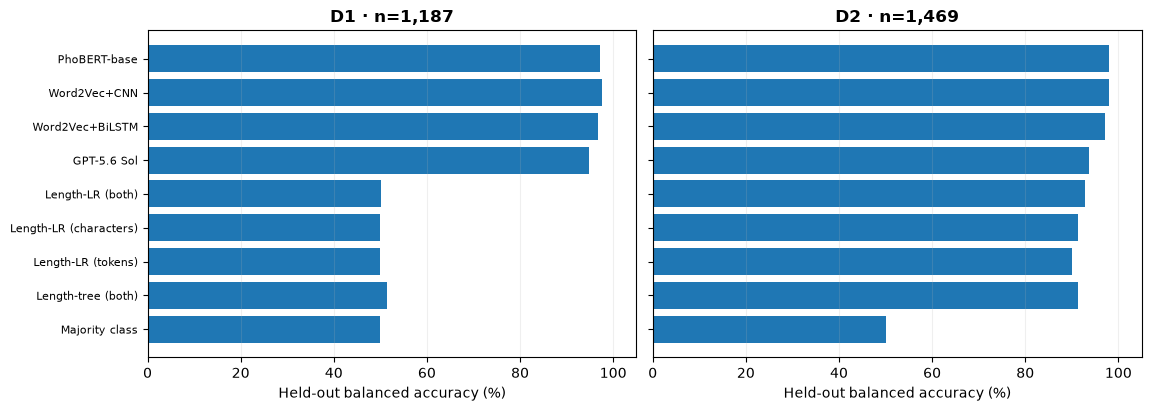

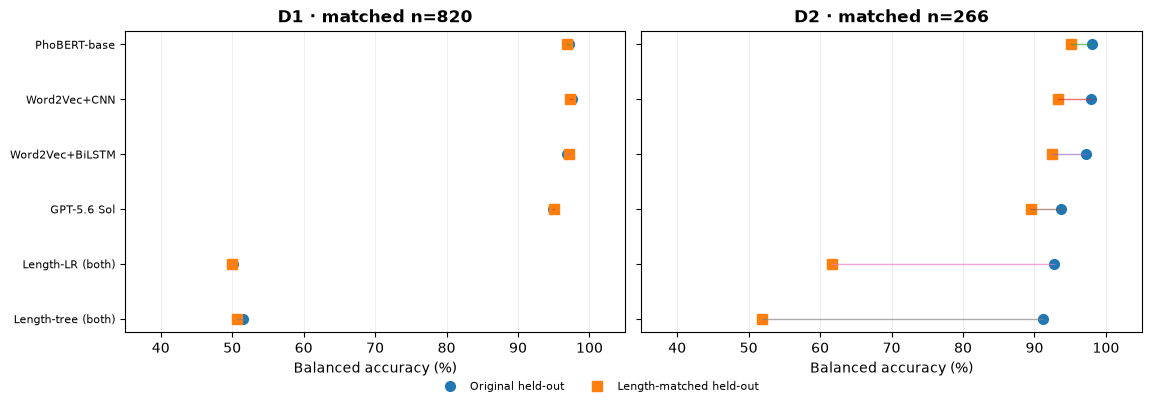

PDF figures:
 - figure_full_vs_length_matched.pdf
 - figure_length_distributions.pdf
 - figure_length_only_vs_saved_models.pdf


In [9]:
# Plot 1: length-only baselines vs saved models — same DL/GPT split.
fig,axs=plt.subplots(1,2,figsize=(11.4,4.0),sharey=True,constrained_layout=True)
selected_order=['PhoBERT-base','Word2Vec+CNN','Word2Vec+BiLSTM','GPT-5.6 Sol',
 'Length-LR (both)','Length-LR (characters)','Length-LR (tokens)','Length-tree (both)','Majority class']
for ax,d in zip(axs,['D1','D2']):
    dd=full_results[full_results.dataset==d].set_index('model').reindex(selected_order).reset_index()
    ax.barh(np.arange(len(dd)),100*dd.balanced_accuracy)
    ax.set_yticks(range(len(dd)),dd.model,fontsize=8)
    ax.set_xlim(0,105); ax.grid(axis='x',alpha=.20)
    ax.set_xlabel('Held-out balanced accuracy (%)')
    ax.set_title(f'{d} · n={int(dd.n.iloc[0]):,}',weight='bold')
axs[0].invert_yaxis()
fig.savefig(OUT/'figure_length_only_vs_saved_models.pdf',bbox_inches='tight')
plt.show()

# Plot 2: within-model original-vs-length-matched performance.
fig,axs=plt.subplots(1,2,figsize=(11.4,3.75),sharey=True,constrained_layout=True)
compare=['PhoBERT-base','Word2Vec+CNN','Word2Vec+BiLSTM','GPT-5.6 Sol',
         'Length-LR (both)','Length-tree (both)']
for ax,d in zip(axs,['D1','D2']):
    m=side_by_side[side_by_side.dataset==d].set_index('model').reindex(compare)
    yy=np.arange(len(compare))
    ax.plot(100*m.balanced_accuracy_full,yy,'o',ms=7,label='Original held-out')
    ax.plot(100*m.balanced_accuracy_matched,yy,'s',ms=7,label='Length-matched held-out')
    for i,(_,row) in enumerate(m.iterrows()):
        ax.plot([100*row.balanced_accuracy_full,100*row.balanced_accuracy_matched],[i,i],lw=1,alpha=.65)
    ax.set_yticks(yy,compare,fontsize=8)
    ax.set_xlim(35,105);ax.grid(axis='x',alpha=.20)
    ax.set_xlabel('Balanced accuracy (%)')
    nmatch=int(matching.loc[matching.dataset==d,'matched_n'].iloc[0])
    ax.set_title(f'{d} · matched n={nmatch:,}',weight='bold')
axs[0].invert_yaxis()
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='lower center',bbox_to_anchor=(0.52,-0.06),ncol=2,frameon=False,fontsize=8)
fig.savefig(OUT/'figure_full_vs_length_matched.pdf',bbox_inches='tight')
plt.show()
print('PDF figures:', *[p.name for p in sorted(OUT.glob('figure_*.pdf'))],sep='\n - ')

## 9 · Interpretation, audit, and manuscript-ready descriptive language

**If length-only models perform well**, report that length is an informative shortcut for the evaluated benchmark. **If semantic models remain strong after length-matching**, it suggests their predictions are not solely explained by document length in the matched overlap region. These analyses **cannot** eliminate source, topical, translation, near-duplicate, or benchmark-construction confounds. Nor do they demonstrate clinical diagnostic validity.

**Matched vs original metrics use different subsets** (and class balance), and should be presented as sensitivity results, not a causal estimate of removing length information. A small D2 overlap limits generalization.

Keep split distinctions clear. Do not silently compare a TF–IDF test set to a DL/GPT length-only baseline or present absent PhoBERT-large matched metrics.

In [10]:
# Non-text run manifest with traceability and minimal output summaries.
manifest={
 'analysis':'length_only_baseline_and_length_matched_test_sensitivity',
 'raw_input_sha256':EXPECTED_SHA256,
 'split_protocol':'train_test_split(test_size=0.2,random_state=42,stratify=sentiment)',
 'matching_caliper':'coarsened-exact fixed log1p(character) bins of width log(1.25)',
 'matched_by':'raw character length and label only; equal-quantile positions within shared log-length bins; without replacement',
 'length_features':'log1p(raw unicode-character count), log1p(whitespace token count)',
 'no_phobert_large_predictions':'PhoBERT-large predictions are absent from supplied repository',
 'tfidf_protocol_different':'TF-IDF legacy preprocessing yields a different outer test split',
 'privacy':'No raw text is saved by this notebook; local row-level IDs can still be sensitive',
 'key_outputs':{
    'baseline':length_baselines[['dataset','model','accuracy','balanced_accuracy','macro_f1']].round(6).to_dict(orient='records'),
    'matching':matching.round(6).to_dict(orient='records')
  }
}
(OUT/'RUN_MANIFEST.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
for d in ['D1','D2']:
    lr=length_baselines.query('dataset == @d and model == "Length-LR (both)"').iloc[0]
    sem=full_results.query('dataset == @d and model == "PhoBERT-base"').iloc[0]
    pairs=matching.loc[matching.dataset==d].iloc[0]
    print(f'{d}: Length-only LR balanced accuracy={lr.balanced_accuracy:.3f}, '
          f'PhoBERT-base={sem.balanced_accuracy:.3f}; '
          f'length-matched held-out sample={int(pairs.matched_n)} '
          f'({pairs.test_coverage:.1%} of test records).')
print('All analyses complete. Review the aggregate CSVs and vector PDFs before manuscript insertion.')

D1: Length-only LR balanced accuracy=0.501, PhoBERT-base=0.971; length-matched held-out sample=820 (69.1% of test records).
D2: Length-only LR balanced accuracy=0.928, PhoBERT-base=0.981; length-matched held-out sample=266 (18.1% of test records).
All analyses complete. Review the aggregate CSVs and vector PDFs before manuscript insertion.
